# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SpaceNet3Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/spacenet_3/train/",
}
dataset = SpaceNet3Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2780


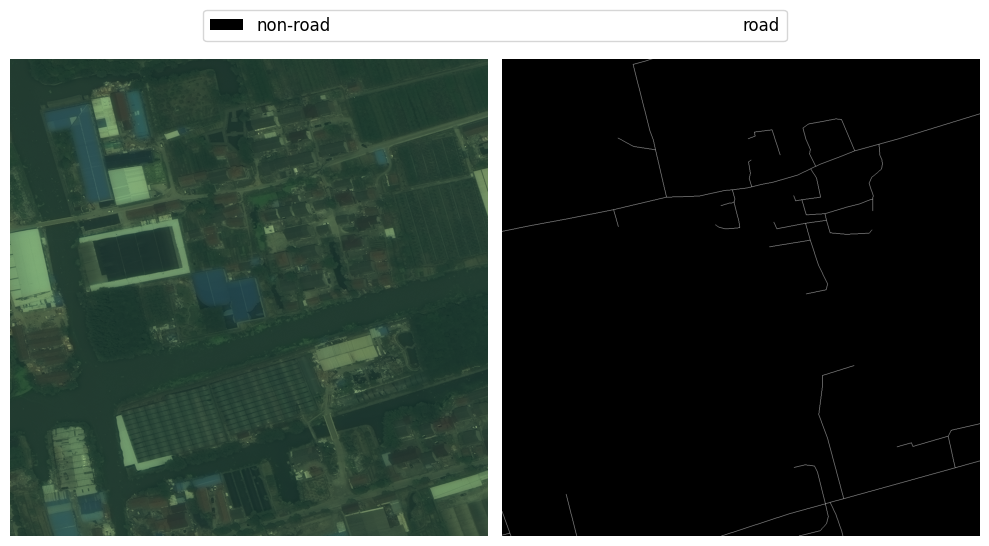

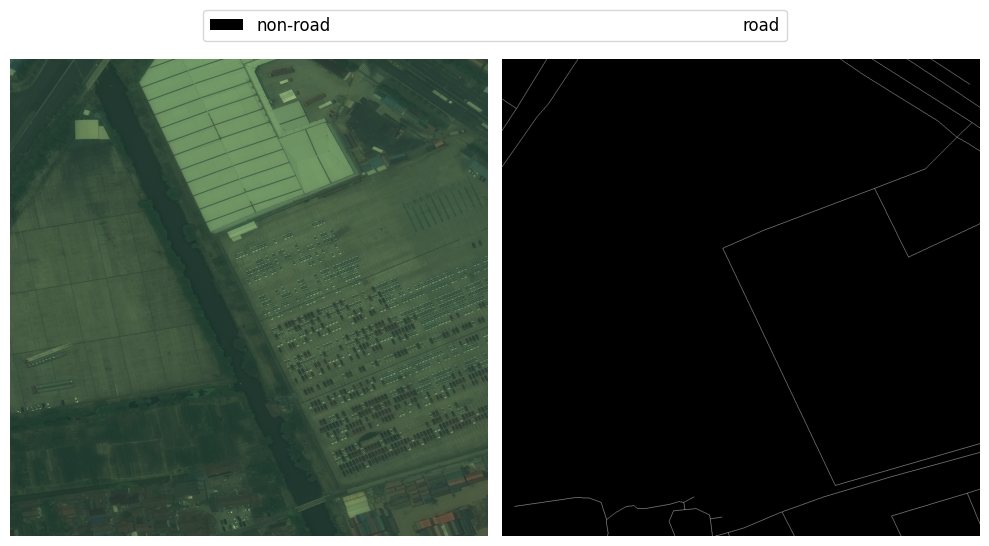

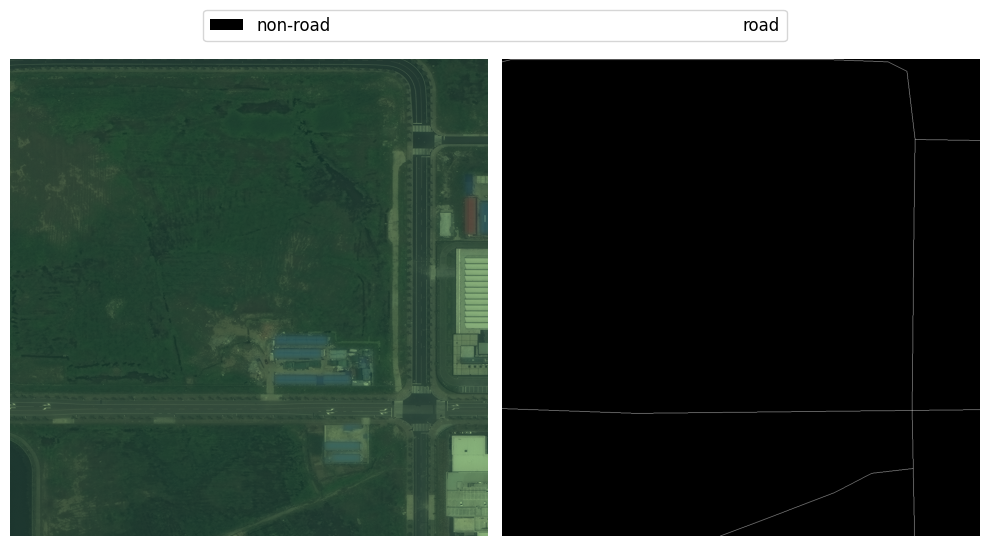

In [31]:
dataset.show_image(150);
dataset.show_image(230);
dataset.show_image(25);

In [38]:
dataset.data_distribution_table()

,Number of pixels
non-road,4621280848
road,76919152


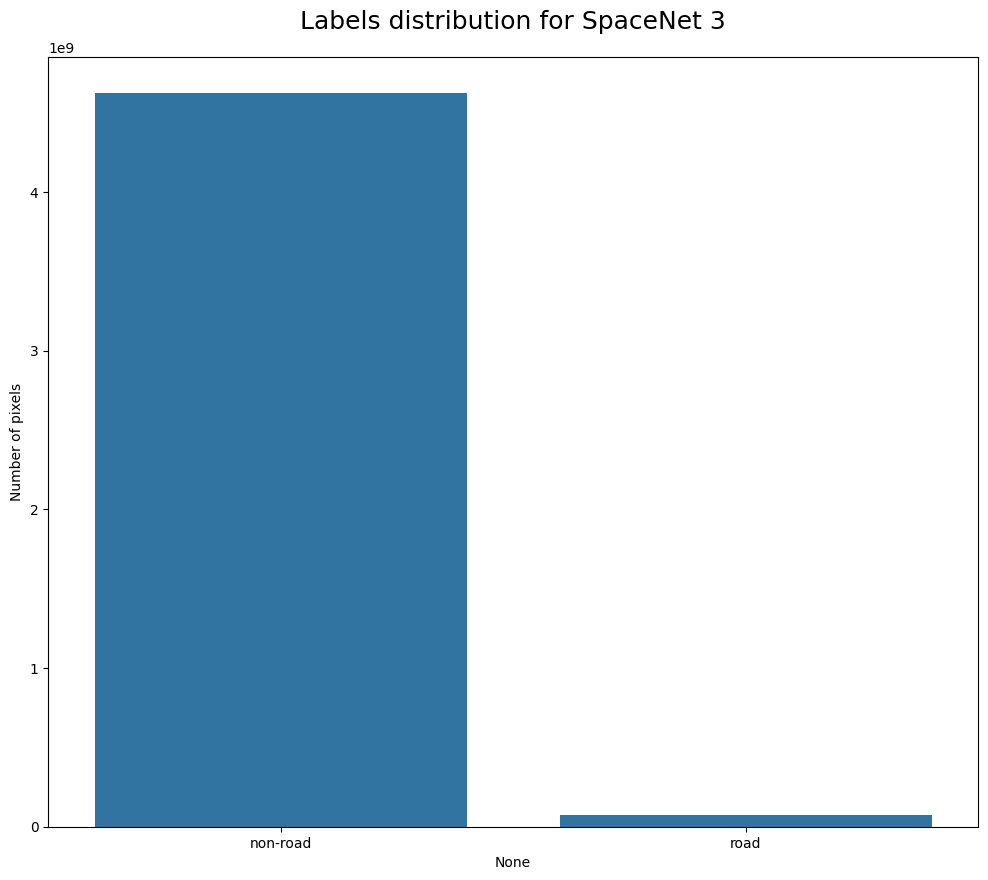

In [39]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/spacenet_3/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet3Dataset(train_dataset_config)

len(train_dataset)

2780

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/SpaceNet3/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-29 06:40:30,711 INFO Starting training.
training: 100%|██████████| 695/695 [01:00<00:00, 11.41it/s]
2025-09-29 06:41:31,739 INFO epoch: 1, time: 61, loss:  0.13670
testing on train set: 100%|██████████| 695/695 [01:11<00:00,  9.65it/s]
2025-09-29 06:42:45,343 INFO IOU:0.928967725172107, IOU mean:0.4644850888698221, IOU per Class:[0.92897018 0.        ]
training: 100%|██████████| 695/695 [01:15<00:00,  9.24it/s]
2025-09-29 06:44:00,538 INFO epoch: 2, time: 75, loss:  0.01907
testing on train set: 100%|██████████| 695/695 [01:15<00:00,  9.26it/s]
2025-09-29 06:45:15,573 INFO IOU:0.928967725172107, IOU mean:0.4644850888698221, IOU per Class:[0.92897018 0.        ]
training: 100%|██████████| 695/695 [01:15<00:00,  9.25it/s]
2025-09-29 06:46:30,735 INFO epoch: 3, time: 75, loss:  0.01156
testing on train set: 100%|██████████| 695/695 [01:16<00:00,  9.13it/s]
2025-09-29 06:47:46,901 INFO IOU:0.928967725172107, IOU mean:0.4644850888698221, IOU per Class:[0.92897018 0.        ]
trainin

0.008226840701892222

## Predictions ##

2025-09-29 07:08:14,810 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet3/checkpoint.pth.tar
2025-09-29 07:08:15,178 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet3/checkpoint.pth.tar at epoch 11
2025-09-29 07:08:15,232 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-29 07:08:15,375 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


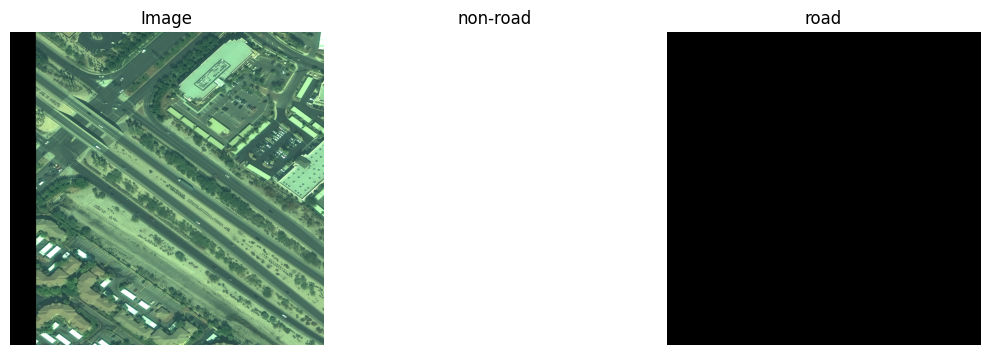

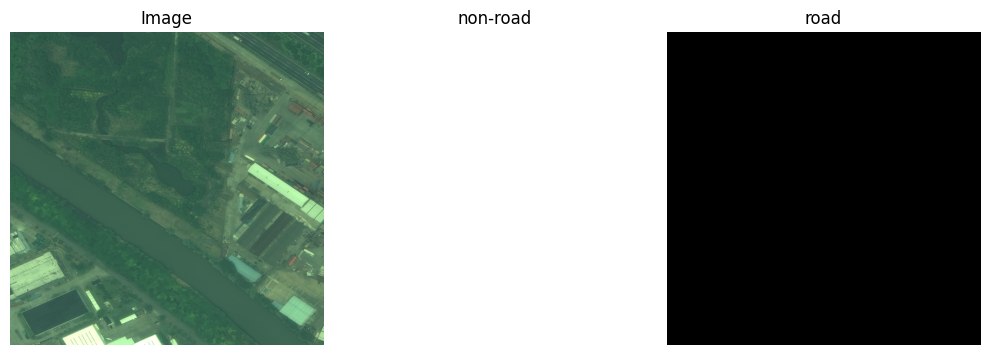

In [ ]:
model_path = "./data/experiments/SpaceNet3/checkpoint.pth.tar"
labels = ["non-road","road"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/spacenet_3/test_public/AOI_2_Vegas/PS-RGB/SN3_roads_test_public_AOI_2_Vegas_PS-RGB_img18.tif').astype(np.float32)/1000
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/spacenet_3/test_public/AOI_4_Shanghai/PS-RGB/SN3_roads_test_public_AOI_4_Shanghai_PS-RGB_img62.tif').astype(np.float32)/1000
fig = model.predict_masks(image, labels, transform)